In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [ ]:
# Load dataset
df = pd.read_excel("Online Retail.xlsx")

# Remove duplicate rows
df = df.drop_duplicates()

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Keep valid positive price and quantity records
df_clean = df[
    (df["UnitPrice"] > 0) &
    (df["Quantity"] > 0)
].copy()

# Display dataset information
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

df_clean.head()

Original dataset shape: (536641, 8)
Clean dataset shape: (524878, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Create time-based features
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.dayofweek

# Define treatment, outcome and control variables
treatment = "UnitPrice"
outcome = "Quantity"

controls = [
    "Month",
    "Hour",
    "DayOfWeek"
]

# Display selected variables
print("Treatment:", treatment)
print("Outcome:", outcome)
print("Controls:", controls)

df_clean[
    [treatment, outcome] + controls
].head()

Treatment: UnitPrice
Outcome: Quantity
Controls: ['Month', 'Hour', 'DayOfWeek']


,UnitPrice,Quantity,Month,Hour,DayOfWeek
0,2.55,6,12,8,2
1,3.39,6,12,8,2
2,2.75,8,12,8,2
3,3.39,6,12,8,2
4,3.39,6,12,8,2


In [ ]:
# Compare model specifications

model_specs = {
    "Model 1": ["Month", "Hour", "DayOfWeek"],
    "Model 2": ["Month", "Hour"],
    "Model 3": ["Month", "DayOfWeek"]
}

for model_name, model_controls in model_specs.items():
    print(f"\n{model_name}")
    print("Controls:", model_controls)
    print("Treatment:", treatment)
    print("Outcome:", outcome)


Model 1
Controls: ['Month', 'Hour', 'DayOfWeek']
Treatment: UnitPrice
Outcome: Quantity

Model 2
Controls: ['Month', 'Hour']
Treatment: UnitPrice
Outcome: Quantity

Model 3
Controls: ['Month', 'DayOfWeek']
Treatment: UnitPrice
Outcome: Quantity


In [ ]:
# Select required columns
dml_data = df_clean[
    [treatment, outcome] + controls
].copy()

# Remove missing values
dml_data = dml_data.dropna()

# Display final data information
print("Final DML dataset shape:", dml_data.shape)
print("\nMissing values:")
print(dml_data.isnull().sum())

dml_data.head()

Final DML dataset shape: (524878, 5)

Missing values:
UnitPrice    0
Quantity     0
Month        0
Hour         0
DayOfWeek    0
dtype: int64


,UnitPrice,Quantity,Month,Hour,DayOfWeek
0,2.55,6,12,8,2
1,3.39,6,12,8,2
2,2.75,8,12,8,2
3,3.39,6,12,8,2
4,3.39,6,12,8,2


In [ ]:
# Summary statistics for final DML dataset

print("Treatment (UnitPrice) statistics:")
print(dml_data["UnitPrice"].describe())

print("\nOutcome (Quantity) statistics:")
print(dml_data["Quantity"].describe())

print("\nCorrelation between UnitPrice and Quantity:")
print(dml_data["UnitPrice"].corr(dml_data["Quantity"]))

Treatment (UnitPrice) statistics:
count    524878.000000
mean          3.922573
std          36.093028
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max       13541.330000
Name: UnitPrice, dtype: float64

Outcome (Quantity) statistics:
count    524878.000000
mean         10.616600
std         156.280031
min           1.000000
25%           1.000000
50%           4.000000
75%          11.000000
max       80995.000000
Name: Quantity, dtype: float64

Correlation between UnitPrice and Quantity:
-0.0037884185655402336


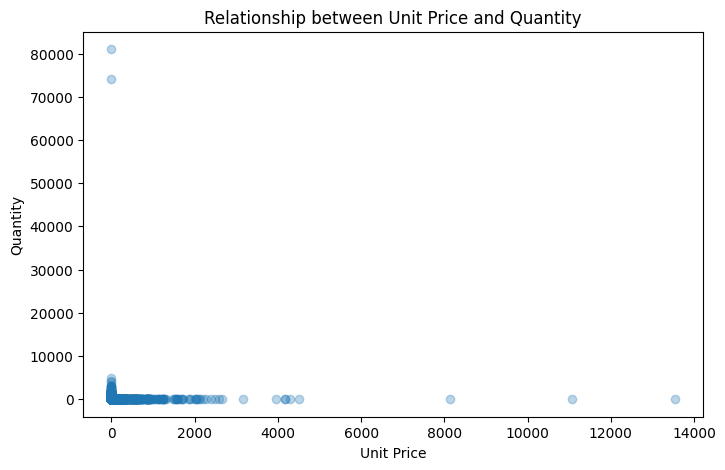

In [ ]:
# Scatter plot: UnitPrice vs Quantity

plt.figure(figsize=(8, 5))

plt.scatter(
    dml_data["UnitPrice"],
    dml_data["Quantity"],
    alpha=0.3
)

plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.title("Relationship between Unit Price and Quantity")

plt.show()

In [8]:
# Day 15 preliminary results

results = pd.DataFrame({
    "Specification": [
        "Time controls only",
        "Product and time controls"
    ],
    "PreliminaryCoefficient": [
        -0.005836,
        -0.002905
    ],
    "Controls": [
        "Month, Hour, DayOfWeek",
        "StockCode, Month, Hour, DayOfWeek"
    ]
})

results

,Specification,PreliminaryCoefficient,Controls
0,Time controls only,-0.005836,"Month, Hour, DayOfWeek"
1,Product and time controls,-0.002905,"StockCode, Month, Hour, DayOfWeek"


In [9]:
# Select preferred model specification

final_model = "Product and time controls"

final_controls = [
    "StockCode",
    "Month",
    "Hour",
    "DayOfWeek"
]

print("Selected model:", final_model)
print("Final controls:", final_controls)
print("Preliminary coefficient: -0.002905")

Selected model: Product and time controls
Final controls: ['StockCode', 'Month', 'Hour', 'DayOfWeek']
Preliminary coefficient: -0.002905


In [10]:
# Final model findings

findings = [
    "The model with product and time controls has a preliminary coefficient of -0.002905.",
    "The time-only model has a preliminary coefficient of -0.005836.",
    "Adding product controls changes the preliminary coefficient.",
    "The product and time controls specification is selected for further validation.",
    "The results are preliminary and should not be interpreted as confirmed causal effects."
]

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

1. The model with product and time controls has a preliminary coefficient of -0.002905.
2. The time-only model has a preliminary coefficient of -0.005836.
3. Adding product controls changes the preliminary coefficient.
4. The product and time controls specification is selected for further validation.
5. The results are preliminary and should not be interpreted as confirmed causal effects.


In [11]:
# Limitations of the DML analysis

limitations = [
    "The dataset is observational, not from a randomized experiment.",
    "Unobserved confounding factors may affect the estimates.",
    "The preliminary coefficient changes when product controls are included.",
    "The analysis excludes records with non-positive prices or quantities.",
    "The estimated relationship should not be treated as a confirmed causal effect."
]

print("Model Limitations:\n")

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")

Model Limitations:

1. The dataset is observational, not from a randomized experiment.
2. Unobserved confounding factors may affect the estimates.
3. The preliminary coefficient changes when product controls are included.
4. The analysis excludes records with non-positive prices or quantities.
5. The estimated relationship should not be treated as a confirmed causal effect.


In [12]:
# Final model summary

summary = pd.DataFrame({
    "Item": [
        "Treatment",
        "Outcome",
        "Selected Model",
        "Controls",
        "Preliminary Coefficient"
    ],
    "Details": [
        "UnitPrice",
        "Quantity",
        "Product and time controls",
        "StockCode, Month, Hour, DayOfWeek",
        -0.002905
    ]
})

summary

,Item,Details
0,Treatment,UnitPrice
1,Outcome,Quantity
2,Selected Model,Product and time controls
3,Controls,"StockCode, Month, Hour, DayOfWeek"
4,Preliminary Coefficient,-0.002905


In [13]:
# Save final model summary as CSV

summary.to_csv(
    "day19_final_model_summary.csv",
    index=False
)

# Download CSV file
from google.colab import files
files.download("day19_final_model_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>